In [2]:
from google.colab import files

uploaded = files.upload()

Saving customer_churn_sample.csv to customer_churn_sample.csv


In [3]:
import pandas as pd

df = pd.read_csv("customer_churn_sample.csv")

print("Dataset loaded successfully!")
print("Rows and Columns:", df.shape)

df.head()

Dataset loaded successfully!
Rows and Columns: (15, 11)


,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes


In [4]:
# 1. Dataset information
print("DATASET INFORMATION")
print("=" * 40)
df.info()

# 2. Missing values
print("\nMISSING VALUES")
print("=" * 40)
print(df.isnull().sum())

# 3. Duplicate records
print("\nDUPLICATE ROWS")
print("=" * 40)
print("Duplicate count:", df.duplicated().sum())

# 4. Statistical summary
print("\nSTATISTICAL SUMMARY")
print("=" * 40)
print(df.describe())

# 5. Unique values in categorical columns
print("\nUNIQUE VALUES")
print("=" * 40)

for column in df.select_dtypes(include="object").columns:
    print(f"\n{column}:")
    print(df[column].unique())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        15 non-null     object 
 1   Gender            15 non-null     object 
 2   Age               15 non-null     int64  
 3   TenureMonths      15 non-null     int64  
 4   SubscriptionType  15 non-null     object 
 5   MonthlyCharges    15 non-null     float64
 6   TotalCharges      15 non-null     float64
 7   ContractType      15 non-null     object 
 8   SupportTickets    15 non-null     int64  
 9   PaymentMethod     15 non-null     object 
 10  Churn             15 non-null     object 
dtypes: float64(2), int64(3), object(6)
memory usage: 1.4+ KB

MISSING VALUES
CustomerID          0
Gender              0
Age                 0
TenureMonths        0
SubscriptionType    0
MonthlyCharges      0
TotalCharges        0
ContractType        0
SupportTicke

In [5]:
# 1. Check invalid values
print("INVALID VALUE CHECK")
print("=" * 40)

print("Age below 18 or above 100:",
      ((df["Age"] < 18) | (df["Age"] > 100)).sum())

print("Negative Tenure:",
      (df["TenureMonths"] < 0).sum())

print("Negative Monthly Charges:",
      (df["MonthlyCharges"] < 0).sum())

print("Negative Total Charges:",
      (df["TotalCharges"] < 0).sum())

print("Negative Support Tickets:",
      (df["SupportTickets"] < 0).sum())

print("Duplicate Customer IDs:",
      df["CustomerID"].duplicated().sum())


# 2. Check TotalCharges consistency
print("\nTOTAL CHARGES VALIDATION")
print("=" * 40)

expected_total = df["MonthlyCharges"] * df["TenureMonths"]

print("Inconsistent Total Charges:",
      (abs(df["TotalCharges"] - expected_total) > 0.01).sum())


# 3. Check outliers using IQR method
print("\nOUTLIER CHECK")
print("=" * 40)

numeric_columns = [
    "Age",
    "TenureMonths",
    "MonthlyCharges",
    "TotalCharges",
    "SupportTickets"
]

for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\n{column}")
    print("Lower Bound:", round(lower_bound, 2))
    print("Upper Bound:", round(upper_bound, 2))
    print("Outlier Count:", len(outliers))

INVALID VALUE CHECK
Age below 18 or above 100: 0
Negative Tenure: 0
Negative Monthly Charges: 0
Negative Total Charges: 0
Negative Support Tickets: 0
Duplicate Customer IDs: 0

TOTAL CHARGES VALIDATION
Inconsistent Total Charges: 0

OUTLIER CHECK

Age
Lower Bound: 4.5
Upper Bound: 72.5
Outlier Count: 0

TenureMonths
Lower Bound: -23.0
Upper Bound: 57.0
Outlier Count: 0

MonthlyCharges
Lower Bound: -47.51
Upper Bound: 212.49
Outlier Count: 0

TotalCharges
Lower Bound: -3689.82
Upper Bound: 7349.46
Outlier Count: 0

SupportTickets
Lower Bound: -3.5
Upper Bound: 8.5
Outlier Count: 0


In [6]:
# Create a copy of the original dataset
df_clean = df.copy()

# Check extra spaces in text columns
text_columns = df_clean.select_dtypes(include="object").columns

print("WHITESPACE CHECK")
print("=" * 40)

for column in text_columns:
    extra_spaces = df_clean[column].astype(str).str.strip()
    count = (df_clean[column].astype(str) != extra_spaces).sum()
    print(f"{column}: {count} extra spaces")

# Remove leading and trailing spaces
for column in text_columns:
    df_clean[column] = df_clean[column].str.strip()

# Final validation
print("\nFINAL DATA VALIDATION")
print("=" * 40)

print("Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Rows:", df_clean.duplicated().sum())
print("Duplicate Customer IDs:",
      df_clean["CustomerID"].duplicated().sum())

print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

print("\nData cleaning completed!")

WHITESPACE CHECK
CustomerID: 0 extra spaces
Gender: 0 extra spaces
SubscriptionType: 0 extra spaces
ContractType: 0 extra spaces
PaymentMethod: 0 extra spaces
Churn: 0 extra spaces

FINAL DATA VALIDATION
Missing Values: 0
Duplicate Rows: 0
Duplicate Customer IDs: 0
Original Shape: (15, 11)
Cleaned Shape: (15, 11)

Data cleaning completed!


In [7]:
# Basic EDA
print("CUSTOMER CHURN ANALYSIS")
print("=" * 40)

print("Total Customers:", len(df_clean))

print("\nChurn Distribution:")
print(df_clean["Churn"].value_counts())

print("\nChurn Percentage:")
print(df_clean["Churn"].value_counts(normalize=True) * 100)

print("\nAverage Age:", round(df_clean["Age"].mean(), 2))

print("Average Tenure:",
      round(df_clean["TenureMonths"].mean(), 2), "months")

print("Average Monthly Charges:",
      round(df_clean["MonthlyCharges"].mean(), 2))

print("Average Support Tickets:",
      round(df_clean["SupportTickets"].mean(), 2))

CUSTOMER CHURN ANALYSIS
Total Customers: 15

Churn Distribution:
Churn
No     8
Yes    7
Name: count, dtype: int64

Churn Percentage:
Churn
No     53.333333
Yes    46.666667
Name: proportion, dtype: float64

Average Age: 39.07
Average Tenure: 18.8 months
Average Monthly Charges: 84.66
Average Support Tickets: 2.53


In [8]:
# Compare churned and retained customers

print("CUSTOMER GROUP COMPARISON")
print("=" * 50)

group_analysis = df_clean.groupby("Churn").agg({
    "Age": "mean",
    "TenureMonths": "mean",
    "MonthlyCharges": "mean",
    "SupportTickets": "mean",
    "TotalCharges": "mean"
}).round(2)

print(group_analysis)

print("\nCONTRACT TYPE BY CHURN")
print("=" * 50)

contract_analysis = pd.crosstab(
    df_clean["ContractType"],
    df_clean["Churn"]
)

print(contract_analysis)

print("\nSUPPORT TICKETS BY CHURN")
print("=" * 50)

ticket_analysis = pd.crosstab(
    df_clean["SupportTickets"],
    df_clean["Churn"]
)

print(ticket_analysis)

CUSTOMER GROUP COMPARISON
         Age  TenureMonths  MonthlyCharges  SupportTickets  TotalCharges
Churn                                                                   
No     46.62         29.12          107.49            1.00       3527.21
Yes    30.43          7.00           58.56            4.29        444.22

CONTRACT TYPE BY CHURN
Churn           No  Yes
ContractType           
Month-to-Month   0    7
One Year         4    0
Two Year         4    0

SUPPORT TICKETS BY CHURN
Churn           No  Yes
SupportTickets         
0                2    0
1                4    0
2                2    0
3                0    2
4                0    2
5                0    2
6                0    1


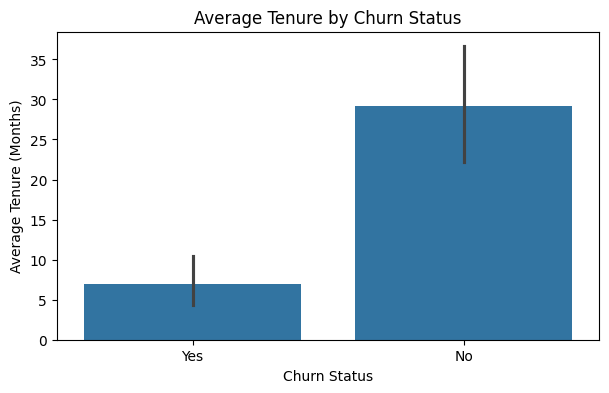

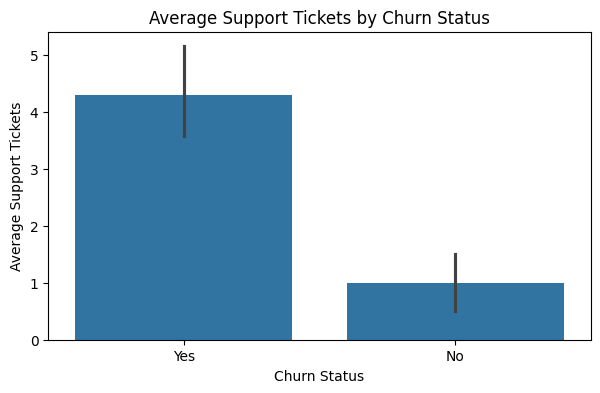

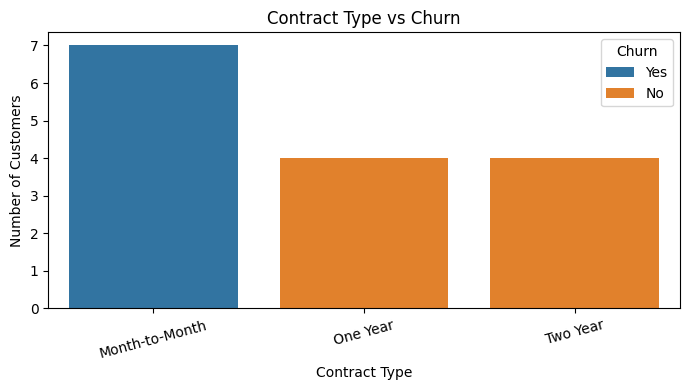

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tenure vs Churn
plt.figure(figsize=(7, 4))
sns.barplot(data=df_clean, x="Churn", y="TenureMonths")
plt.title("Average Tenure by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Average Tenure (Months)")
plt.show()

# 2. Support Tickets vs Churn
plt.figure(figsize=(7, 4))
sns.barplot(data=df_clean, x="Churn", y="SupportTickets")
plt.title("Average Support Tickets by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Average Support Tickets")
plt.show()

# 3. Contract Type vs Churn
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, x="ContractType", hue="Churn")
plt.title("Contract Type vs Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [10]:
df_clean.to_csv("customer_churn_cleaned.csv", index=False)

print("Cleaned CSV created successfully!")

Cleaned CSV created successfully!


In [11]:
from google.colab import files
files.download("customer_churn_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Customer Churn Dataset – Data Quality Report

## 1. Dataset Overview
- Dataset Name: Customer Churn Sample Dataset
- Total Records: 15
- Total Columns: 11
- Analysis Tool: Python, Pandas, Matplotlib
- Dataset Type: Customer Churn Data

## 2. Data Quality Assessment
- Missing Values: 0
- Duplicate Rows: 0
- Duplicate Customer IDs: 0
- Invalid Values: 0
- Inconsistent Total Charges: 0
- Outliers: None detected using the IQR method
- Extra Whitespace: None detected

## 3. Data Cleaning
The dataset was examined for missing values, duplicate records, invalid values, inconsistent data, and extra whitespace.

A separate cleaned dataset was created using a copy of the original dataset. No records were removed because no data quality issues were identified.

All 15 records and 11 columns were retained.

## 4. Exploratory Data Analysis

- Total Customers: 15
- Churned Customers: 7
- Retained Customers: 8
- Churn Rate: 46.67%
- Retention Rate: 53.33%
- Average Age: 39.07 years
- Average Tenure: 18.8 months
- Average Monthly Charges: ₹84.66
- Average Support Tickets: 2.53

## 5. Key Findings

- All 7 month-to-month contract customers in this sample churned.
- Customers who churned had an average tenure of 7 months.
- Customers who churned had an average of 4.29 support tickets.
- Retained customers had an average tenure of 29.12 months.
- Retained customers had an average of 1 support ticket.

## 6. Limitations

The dataset contains only 15 customer records. Therefore, the findings are descriptive and cannot be generalized to a larger customer population.

The analysis does not establish causal relationships between customer characteristics and churn.

## 7. Conclusion

The dataset passed the data quality checks. No missing, duplicate, invalid, inconsistent, or IQR-based outlier records were identified.

The cleaned dataset is ready for further exploratory analysis. The analysis highlights differences between churned and retained customers, particularly in tenure, support tickets, and contract type.


In [13]:
import pandas as pd

df = pd.read_csv("customer_churn_sample.csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
  CustomerID  Gender  Age  TenureMonths SubscriptionType  MonthlyCharges  \
0  CUST-1001  Female   34            12            Basic           49.99   
1  CUST-1002    Male   45            24              Pro           79.99   
2  CUST-1003  Female   29             6            Basic           49.99   
3  CUST-1004    Male   52            36       Enterprise          149.99   
4  CUST-1005  Female   41             8              Pro           79.99   

   TotalCharges    ContractType  SupportTickets  PaymentMethod Churn  
0        599.88  Month-to-Month               3    Credit Card   Yes  
1       1919.76        One Year               1  Bank Transfer    No  
2        299.94  Month-to-Month               5            UPI   Yes  
3       5399.64        Two Year               0    Credit Card    No  
4        639.92  Month-to-Month               4     Debit Card   Yes  
